# Weight/mass loss Preprocessing

**Author:** Lab of Farm Structures
**Date:** 2026-11

## Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import math
import re
import warnings; warnings.filterwarnings("ignore")

## Import Data

In [6]:
database = 'Biodegradation_database_PBS_and_real_environments_MK_test'

## Create DataFrames for data points and properties

In [9]:
# Physicochemical properties DataFrame
df_mat = pd.read_excel(f'{database}.xlsx', sheet_name='Materials')

# Environmental properties DataFrame
df_test = pd.read_excel(f'{database}.xlsx', sheet_name='Test_Conditions')

# weight loss percentage DataFrame
df_weight = pd.read_excel(f'{database}.xlsx', sheet_name='Weight_Loss_Timeseries')

## Drop duplicates and remove multiple study+instance case (keep first)

In [11]:
print("Enviromental Properties, rows before:", df_mat.shape[0])
df_mat = df_mat.drop_duplicates()
print("Enviromental Properties, rows after:", df_mat.shape[0])

Enviromental Properties, rows before: 62
Enviromental Properties, rows after: 62


In [13]:
print("Physicochemical Properties, rows before:", df_test.shape[0])
df_test = df_test.drop_duplicates(subset=['study_id', 'sample_id'])
print("Physicochemical Properties, rows after:", df_test.shape[0])

Physicochemical Properties, rows before: 65
Physicochemical Properties, rows after: 63


## Merge physicochemical & enviromental properties

In [16]:
df_merged_prop = pd.merge(df_mat, df_test,  on=['study_id', 'sample_id'], how='left')
df_merged_prop.tail()

,sample_id,study_id,sample_name_in_paper,formulation_ratio_wt,polymer_family,HV_content_mol_pct,HB_content_mol_pct,HHx_content_mol_pct,polymer_wt_pct,additive1_name,...,salinity_ppt,dissolved_oxygen_mg_L,water_depth_m,flow_regime,site_location,microbial_community_notes,test_duration_days,n_timepoints,link_check,notes_y
57,S012-M11,S012,P(3HB)/WF 10/90,10/90,PHB,0.0,100.0,0,10.0000,Wood flour (Pinus sibirica),...,NaN,NaN,NaN,NaN,"Minderlinskoye field lab, Krasnoyarsk, Siberia...",NaN,240.0,4.0,NaN,Agro-transformed forest-steppe soil (P 280 mg/...
58,S013-M01,S013,P0,100.0/0.0/0.0 (PHBV/nHAp/SF),PHBV,2.0,98.0,0,100.0000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,28.0,1.0,OK,"Medium = DEIONISED WATER (not PBS), 37 C water..."
59,S013-M02,S013,P2,78.9/10.5/10.5 (PHBV/nHAp/SF),PHBV,2.0,98.0,0,78.9474,Nano-hydroxyapatite (nHAp),...,NaN,NaN,NaN,NaN,NaN,NaN,28.0,1.0,OK,"Medium = DEIONISED WATER (not PBS), 37 C water..."
60,S013-M03,S013,P5,60.0/20.0/20.0 (PHBV/nHAp/SF),PHBV,2.0,98.0,0,60.0000,Nano-hydroxyapatite (nHAp),...,NaN,NaN,NaN,NaN,NaN,NaN,28.0,1.0,OK,"Medium = DEIONISED WATER (not PBS), 37 C water..."
61,S014-M01,S014,UGR-04,15.5/83.7/0.8 (BC/gelatin/probiotic),Natural polymer,NaN,NaN,0,99.2000,Lactobacillus fermentum CECT 285 (probiotic),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"PBS 1X pH 7.4 at 37 C, 10 days. Medium volume,..."


## Merge properties with t,y values

In [19]:
df_weight.columns

Index(['obs_id', 'test_id', 'study_id', 'sample_id', 'environment_group',
       'environment_class', 'time_value', 'time_unit', 'time_days',
       'weight_loss_pct', 'weight_loss_sd_pct', 'weight_remaining_pct',
       'extraction_method', 'figure_or_table_ref', 'qc_flag', 'notes',
       'output_metric'],
      dtype='str')

In [21]:
df_merged_fnl = df_merged_prop.merge(
    df_weight[['study_id', 'sample_id', 'environment_group', 'time_days','weight_loss_pct']],
    on=['study_id', 'sample_id'],
    how='left'
)
df_merged_fnl = df_merged_fnl.dropna(subset=['time_days', 'weight_loss_pct'])
df_merged_fnl.tail()

,sample_id,study_id,sample_name_in_paper,formulation_ratio_wt,polymer_family,HV_content_mol_pct,HB_content_mol_pct,HHx_content_mol_pct,polymer_wt_pct,additive1_name,...,flow_regime,site_location,microbial_community_notes,test_duration_days,n_timepoints,link_check,notes_y,environment_group_y,time_days,weight_loss_pct
263,S014-M01,S014,UGR-04,15.5/83.7/0.8 (BC/gelatin/probiotic),Natural polymer,NaN,NaN,0,99.2,Lactobacillus fermentum CECT 285 (probiotic),...,NaN,NaN,NaN,NaN,NaN,NaN,"PBS 1X pH 7.4 at 37 C, 10 days. Medium volume,...",In vitro,4.0,43.4700
264,S014-M01,S014,UGR-04,15.5/83.7/0.8 (BC/gelatin/probiotic),Natural polymer,NaN,NaN,0,99.2,Lactobacillus fermentum CECT 285 (probiotic),...,NaN,NaN,NaN,NaN,NaN,NaN,"PBS 1X pH 7.4 at 37 C, 10 days. Medium volume,...",In vitro,7.0,51.5700
265,S014-M01,S014,UGR-04,15.5/83.7/0.8 (BC/gelatin/probiotic),Natural polymer,NaN,NaN,0,99.2,Lactobacillus fermentum CECT 285 (probiotic),...,NaN,NaN,NaN,NaN,NaN,NaN,"PBS 1X pH 7.4 at 37 C, 10 days. Medium volume,...",In vitro,10.0,60.0500
266,S014-M01,S014,UGR-04,15.5/83.7/0.8 (BC/gelatin/probiotic),Natural polymer,NaN,NaN,0,99.2,Lactobacillus fermentum CECT 285 (probiotic),...,NaN,NaN,NaN,NaN,NaN,NaN,"PBS 1X pH 7.4 at 37 C, 10 days. Medium volume,...",In vitro,15.0,69.0460
267,S014-M01,S014,UGR-04,15.5/83.7/0.8 (BC/gelatin/probiotic),Natural polymer,NaN,NaN,0,99.2,Lactobacillus fermentum CECT 285 (probiotic),...,NaN,NaN,NaN,NaN,NaN,NaN,"PBS 1X pH 7.4 at 37 C, 10 days. Medium volume,...",In vitro,22.0,76.9796


## Drop duplicates

In [24]:
df_merged_fnl = df_merged_fnl.drop_duplicates()

## Remove studies 9 and 11, Keep only studies with cellulose-based polymers

In [27]:
df_merged_fnl = df_merged_fnl[
    ~df_merged_fnl["study_id"].isin(["S009", "S011"])
    & df_merged_fnl["polymer_family"].isin(["Cellulose", "Natural polymer"])
].reset_index(drop=True)

print(df_merged_fnl.shape, sorted(df_merged_fnl["study_id"].unique()))

(140, 98) ['S002', 'S005', 'S006', 'S008', 'S010', 'S012', 'S014']


## Replace N/A values with nan

In [29]:
df_merged_fnl = df_merged_fnl.replace(
    ["N/A", "n/a", "NA", "na"],
    np.nan
)

## Fix typos, excl. special characters

In [32]:
def clean_column_name(col):
    col = col.strip().lower()
    col = re.sub(r'[%()]', '', col)        # remove % ( )
    col = re.sub(r'[\/]', '_', col)        # / → _
    col = re.sub(r'\s+', '_', col)         # spaces → _
    col = re.sub(r'[^a-z0-9_]', '', col)   # remove remaining special chars
    col = re.sub(r'_+', '_', col)           # collapse multiple _
    col = col.strip('_')
    return col

def clean_cell_value(val):
    if isinstance(val, str):
        val = val.strip().lower()
        val = re.sub(r'[%()]', '', val)       # remove % ( )
        val = re.sub(r'[\/]', '_', val)       # / → _
        val = re.sub(r'\s+', '_', val)        # spaces → _
        val = re.sub(r'[^a-z0-9_]', '', val)  # remove remaining special chars
        val = re.sub(r'_+', '_', val)         # collapse multiple _
        val = val.strip('_')
    return val

In [34]:
df_merged_fnl.columns = [clean_column_name(c) for c in df_merged_fnl.columns]
df_merged_fnl.head()

,sample_id,study_id,sample_name_in_paper,formulation_ratio_wt,polymer_family,hv_content_mol_pct,hb_content_mol_pct,hhx_content_mol_pct,polymer_wt_pct,additive1_name,...,flow_regime,site_location,microbial_community_notes,test_duration_days,n_timepoints,link_check,notes_y,environment_group_y,time_days,weight_loss_pct
0,S002-M02,S002,PHB/BC1%,NaN,Natural polymer,0.0,100.0,0,80.2,Tributyl citrate (TBC),...,NaN,NaN,NaN,20.0,5.0,NaN,20 mm discs in sealed tubes with 2 mL PBS; was...,In vitro,1.0,0.18
1,S002-M02,S002,PHB/BC1%,NaN,Natural polymer,0.0,100.0,0,80.2,Tributyl citrate (TBC),...,NaN,NaN,NaN,20.0,5.0,NaN,20 mm discs in sealed tubes with 2 mL PBS; was...,In vitro,5.0,0.97
2,S002-M02,S002,PHB/BC1%,NaN,Natural polymer,0.0,100.0,0,80.2,Tributyl citrate (TBC),...,NaN,NaN,NaN,20.0,5.0,NaN,20 mm discs in sealed tubes with 2 mL PBS; was...,In vitro,10.0,1.75
3,S002-M02,S002,PHB/BC1%,NaN,Natural polymer,0.0,100.0,0,80.2,Tributyl citrate (TBC),...,NaN,NaN,NaN,20.0,5.0,NaN,20 mm discs in sealed tubes with 2 mL PBS; was...,In vitro,15.0,1.90
4,S002-M02,S002,PHB/BC1%,NaN,Natural polymer,0.0,100.0,0,80.2,Tributyl citrate (TBC),...,NaN,NaN,NaN,20.0,5.0,NaN,20 mm discs in sealed tubes with 2 mL PBS; was...,In vitro,20.0,2.35


## Define keys, features and target

In [37]:
keys   = ["study_id", "sample_id"]   # kept for leave-one-instance/study-out
target = ["weight_loss_pct"]
feats  = ["time_days", "environment_class", "polymer_family", "polymer_wt_pct",
          "additive1_type", "additive1_wt_pct", "morphology", "cellulose_component",
          "crystallinity_pct", "temperature_c"]

df_merged_fnl = df_merged_fnl[keys + feats + target].copy()

In [39]:
df_clean = df_merged_fnl.copy()

# apply only to object (string) columns
obj_cols = df_clean.select_dtypes(include='object').columns

df_clean[obj_cols] = df_clean[obj_cols].apply( lambda col: col.map(clean_cell_value) )

In [41]:
df_clean['additive1_type'].value_counts()

additive1_type
antimicrobial_bioactive    56
stabilizer                 24
plasticizer                10
Name: count, dtype: int64

In [43]:
df_clean.loc[df_clean['additive1_wt_pct'].isna(), 'additive1_wt_pct'] = 0
df_clean['additive1_wt_pct'] = pd.to_numeric(df_clean['additive1_wt_pct'],errors='coerce')
df_clean['additive1'] = df_clean['additive1_wt_pct'].apply(lambda x: 'yes' if x > 0 else 'no')
df_clean.loc[df_clean['additive1'] == 'no', 'additive1_type'] = 'no_additive'

## Drop features with more than 80% missing values

In [46]:
df_clean = df_clean.loc[:, df_clean.isna().mean() < 0.20]
df_clean.columns

Index(['study_id', 'sample_id', 'time_days', 'environment_class',
       'polymer_family', 'polymer_wt_pct', 'additive1_type',
       'additive1_wt_pct', 'morphology', 'cellulose_component',
       'weight_loss_pct', 'additive1'],
      dtype='str')

## Feature engineering

In [49]:
df_clean['environment_class'].value_counts()

environment_class
soil                  86
in_vitro_pbs          42
compost_industrial    12
Name: count, dtype: int64

In [51]:
df_clean['polymer_family'].value_counts()

polymer_family
natural_polymer    124
cellulose           16
Name: count, dtype: int64

In [53]:
df_clean['additive1_type'].value_counts()

additive1_type
antimicrobial_bioactive    56
no_additive                50
stabilizer                 24
plasticizer                10
Name: count, dtype: int64

In [55]:
df_clean['morphology'].value_counts()

morphology
film            94
plate_coupon    16
other           12
foam_porous     10
powder           8
Name: count, dtype: int64

In [57]:
morphology_mapping = {
    "film": "film",
    "plate_coupon": "plate_coupon",
    "other": "other",
    "foam_porous": "foam_porous",
    "powder": "other"
}

# Apply mapping
df_clean["morphology"] = (
    df_clean["morphology"]
    .str.strip()           # remove leading/trailing spaces
    .map(morphology_mapping)
    .fillna("uncategorized")
)
df_clean['morphology'].value_counts()

morphology
film            94
other           20
plate_coupon    16
foam_porous     10
Name: count, dtype: int64

In [59]:
df_clean['cellulose_component'].value_counts()

cellulose_component
bacterial_cellulose     70
cellulose_derivative    54
nanocellulose            8
cellulose_fibres         4
wood_flour               4
Name: count, dtype: int64

In [61]:
cellulose_mapping = {
    "bacterial_cellulose":   "bacterial_cellulose",
    "cellulose_derivative":  "cellulose_derivative",
    "nanocellulose":         "nanocellulose",
    "wood_flour":            "other_lignocellulosic",
    "cellulose_fibres":      "other_lignocellulosic",
}

# Apply mapping (labels normalised first, so "Wood flour" and "wood_flour" both match)
df_clean["cellulose_component"] = (
    df_clean["cellulose_component"]
    .str.strip()
    .str.lower()
    .str.replace(r"[\s/-]+", "_", regex=True)
    .map(cellulose_mapping)
    .fillna("uncategorized")
)
df_clean["cellulose_component"].value_counts()

cellulose_component
bacterial_cellulose      70
cellulose_derivative     54
nanocellulose             8
other_lignocellulosic     8
Name: count, dtype: int64

## Final feature selection and Target value

In [64]:
df_clean.columns

Index(['study_id', 'sample_id', 'time_days', 'environment_class',
       'polymer_family', 'polymer_wt_pct', 'additive1_type',
       'additive1_wt_pct', 'morphology', 'cellulose_component',
       'weight_loss_pct', 'additive1'],
      dtype='str')

In [66]:
features = [
    'study_id', 'sample_id', 'time_days', 'environment_class',
       'polymer_family', 'polymer_wt_pct', 'additive1_type',
       'additive1_wt_pct', 'morphology', 'cellulose_component'
]

target = 'weight_loss_pct'

measure_unit = '%'

In [68]:
# Create cleaned DataFrame
df_new = df_clean[features + [target]]

df_new.info()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   study_id             140 non-null    str    
 1   sample_id            140 non-null    str    
 2   time_days            140 non-null    float64
 3   environment_class    140 non-null    str    
 4   polymer_family       140 non-null    str    
 5   polymer_wt_pct       140 non-null    float64
 6   additive1_type       140 non-null    str    
 7   additive1_wt_pct     140 non-null    float64
 8   morphology           140 non-null    str    
 9   cellulose_component  140 non-null    str    
 10  weight_loss_pct      140 non-null    float64
dtypes: float64(4), str(7)
memory usage: 12.2 KB


## Drop rows with nan value

In [71]:
mask = (
    df_new[target].notna() &
    df_new[features].notna().all(axis=1)
)

# Create final dataset
df_final = df_new.loc[mask, features + [target]]
df_final.columns = df_final.columns.str.replace(' ', '_', regex=False)

# Check the DataFrame
df_final.tail()

,study_id,sample_id,time_days,environment_class,polymer_family,polymer_wt_pct,additive1_type,additive1_wt_pct,morphology,cellulose_component,weight_loss_pct
135,s014,s014m01,4.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,43.4700
136,s014,s014m01,7.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,51.5700
137,s014,s014m01,10.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,60.0500
138,s014,s014m01,15.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,69.0460
139,s014,s014m01,22.0,in_vitro_pbs,natural_polymer,99.2,antimicrobial_bioactive,0.8,other,bacterial_cellulose,76.9796


## Process time and weight loss values, round, float, etc

In [74]:
df_final['weight_loss_pct'] = (
    df_final['weight_loss_pct']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.replace('±', '', regex=False)
    .str.replace(r'\s*\d+$', '', regex=True)   # remove trailing uncertainty (like "2")
    .str.strip()
)

df_final['weight_loss_pct'] = pd.to_numeric(df_final['weight_loss_pct'], errors='coerce')

df_final['time_days'] = (
    df_final['time_days']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.replace('±', '', regex=False)
    .str.replace(r'\s*\d+$', '', regex=True)   # remove trailing uncertainty (like "2")
    .str.strip()
)

df_final['time_days'] = pd.to_numeric(df_final['time_days'], errors='coerce')

# Convert certain values to float
df_final['time_days'] = df_final['time_days'].astype(float)
df_final['weight_loss_pct'] = df_final['weight_loss_pct'].astype(float)
df_final['additive1_wt_pct'] = df_final['additive1_wt_pct'].astype(float)

# Check the DataFrame
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   study_id             140 non-null    str    
 1   sample_id            140 non-null    str    
 2   time_days            140 non-null    float64
 3   environment_class    140 non-null    str    
 4   polymer_family       140 non-null    str    
 5   polymer_wt_pct       140 non-null    float64
 6   additive1_type       140 non-null    str    
 7   additive1_wt_pct     140 non-null    float64
 8   morphology           140 non-null    str    
 9   cellulose_component  140 non-null    str    
 10  weight_loss_pct      140 non-null    float64
dtypes: float64(4), str(7)
memory usage: 12.2 KB


## Plot feature distribution

In [77]:
# Numerical columns
numerical_cols_lst = df_final.select_dtypes(include=[np.number]).columns.tolist()
# numerical_cols_lst.remove(target)
# Categorical columns
categorical_cols_lst = df_final.select_dtypes(include=['object', 'category']).columns.tolist()

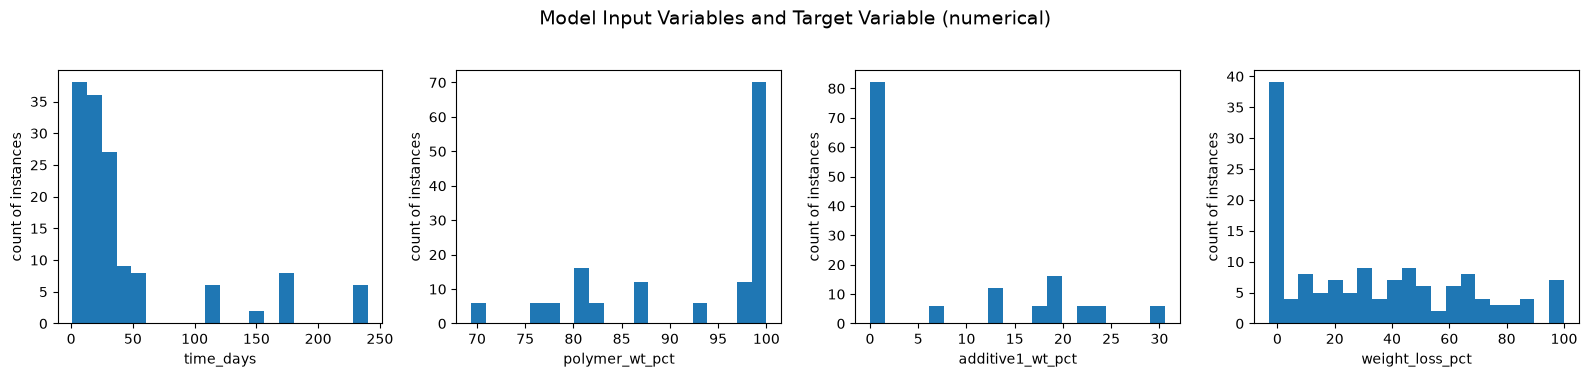

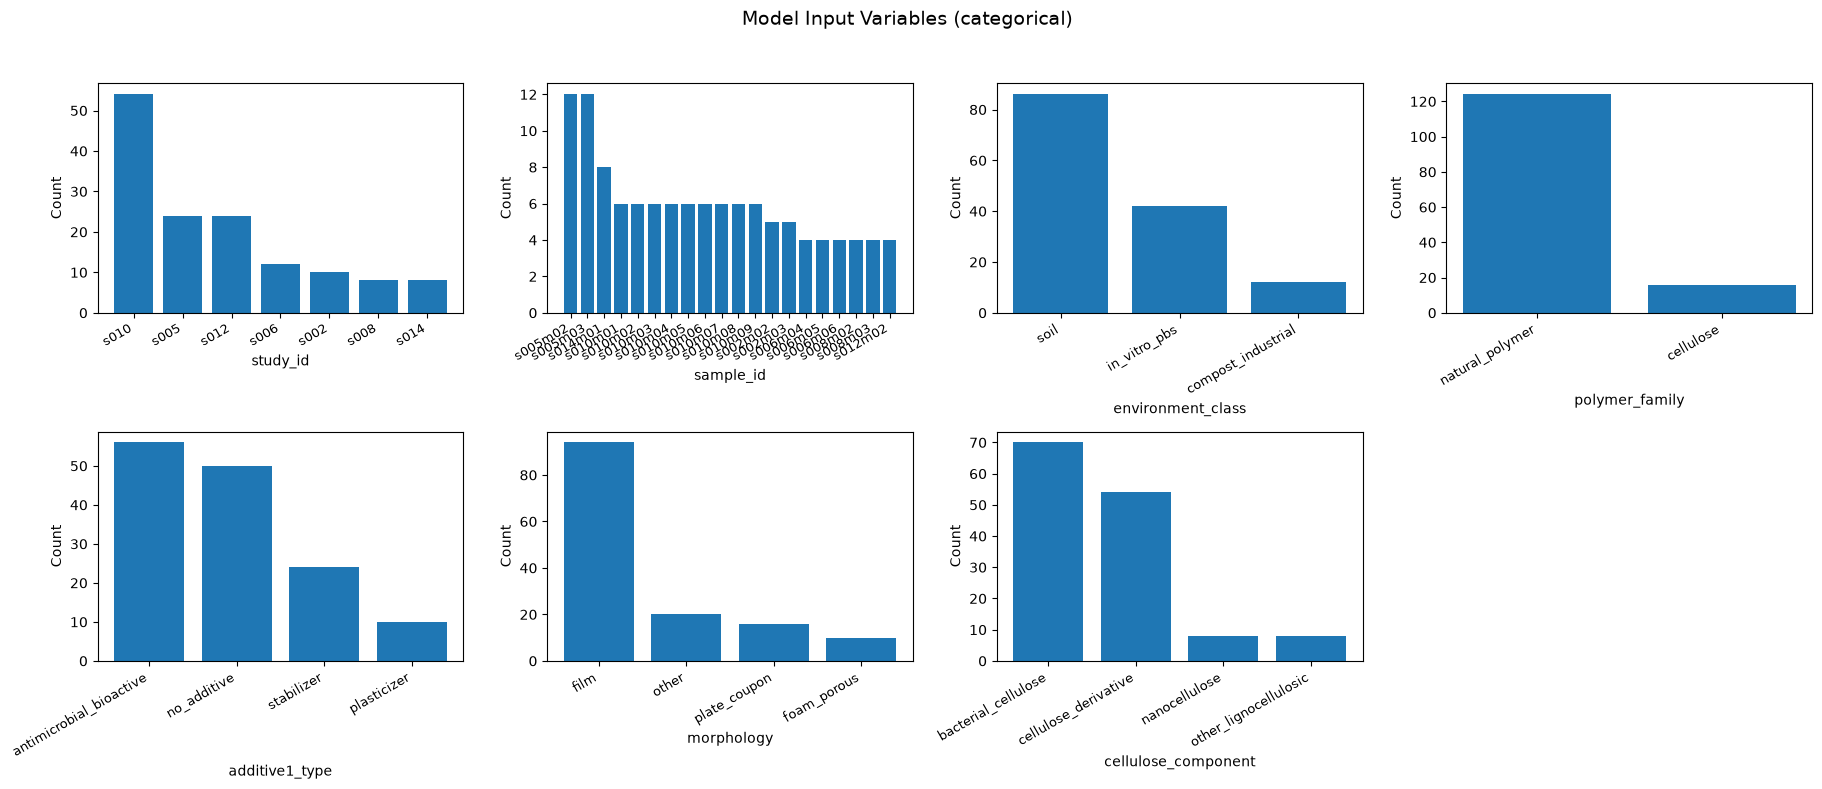

In [79]:
def plot_feature_distributions(
    df: pd.DataFrame,
    numerical_cols,
    categorical_cols,
    title_numeric="Model Input Variables and Target Variable (numerical)",
    title_categorical="Model Input Variables (categorical)",
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,   # cap bars for very high-cardinality cats
):
    # ---------- helper to grid-plot ----------
    def _grid_dims(n, max_cols):
        cols = min(max_cols, max(1, n))
        rows = int(math.ceil(n / cols))
        return rows, cols

    # ---------- NUMERICAL ----------
    if len(numerical_cols) > 0:
        n = len(numerical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.0*cols, 3.8*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_numeric, fontsize=14, y=0.98)

        for i, col in enumerate(numerical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            x = df[col].dropna().values
            ax.hist(x, bins=bins)
            #ax.set_title(str(col), fontsize=10)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # ---------- CATEGORICAL ----------
    if len(categorical_cols) > 0:
        n = len(categorical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.6*cols, 4.0*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_categorical, fontsize=14, y=0.98)

        for i, col in enumerate(categorical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            vc = (df[col].astype(str).replace("nan", np.nan)
                                 .value_counts(dropna=False)
                                 .head(top_k_categories))
            ax.bar(range(len(vc)), vc.values)
            ax.set_xticks(range(len(vc)))
            ax.set_xticklabels(vc.index.astype(str), rotation=30, ha="right", fontsize=9)
            #ax.set_title(str(col), fontsize=10)
            ax.set_ylabel("Count")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

plot_feature_distributions(
    df_final,
    numerical_cols_lst,
    categorical_cols_lst,
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,
)

## Remove features with only one value

In [81]:
constant_cols = df_final.columns[df_final.nunique(dropna=True) <= 1]
print("Removed columns:", list(constant_cols))
df_final = df_final.drop(columns=constant_cols)

Removed columns: []


In [83]:
df_final.columns

Index(['study_id', 'sample_id', 'time_days', 'environment_class',
       'polymer_family', 'polymer_wt_pct', 'additive1_type',
       'additive1_wt_pct', 'morphology', 'cellulose_component',
       'weight_loss_pct'],
      dtype='str')

## Reorder columns

In [86]:
first_cols = ['time_days', 'weight_loss_pct']
df_final = df_final[first_cols + [c for c in df_final.columns if c not in first_cols]]
df_final.columns

Index(['time_days', 'weight_loss_pct', 'study_id', 'sample_id',
       'environment_class', 'polymer_family', 'polymer_wt_pct',
       'additive1_type', 'additive1_wt_pct', 'morphology',
       'cellulose_component'],
      dtype='str')

## Save

In [88]:
df_final.to_csv('weight_loss_cellulose_LM.csv', index=False)